<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch5_linear_est_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Scalar linear estimation with the correct model (Victor Z and Jaron T, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $(x_\omega,y_\omega)$, $S$ | `x_omega`, `y_omega`, `S` | observation pairs |
| $\theta$, $\sigma$ | `theta`, `sigma` | true slope and noise SD ($\sigma^2=0.0625$) |
| $\hat{\theta}=\sum_\omega x_\omega y_\omega/\sum_\omega x_\omega^2$ | `theta_hat` | MLE (least squares) |
| $\hat{y}_\omega=\hat{\theta}x_\omega$, $\hat{\epsilon}_\omega$ | `y_hat`, `eps_hat` | predictions and residuals |
| $SSE(\theta)$ | `SSE` | sum of squared errors |

**Note:** This notebook reproduces Example 5.1 (Section 5.1.1) of *Statistics for Chemical Engineers*: least-squares estimation of theta in Y = theta*X + noise, with true theta = 2.

**The concept.** The model is $Y=\theta X+\epsilon$ with $\epsilon\sim\mathcal{N}(0,\sigma^2)$. The likelihood of the data is

$$L(\theta)=\prod_\omega\frac{1}{\sqrt{2\pi}\sigma}\exp\left(-\frac{(y_\omega-\theta x_\omega)^2}{2\sigma^2}\right),$$

so maximizing $\log L$ is minimizing $SSE(\theta)=\frac{1}{2}\sum_\omega(y_\omega-\theta x_\omega)^2$. Setting $\frac{d\,SSE}{d\theta}=-\sum_\omega x_\omega(y_\omega-\theta x_\omega)=0$ gives $\hat{\theta}=\sum_\omega x_\omega y_\omega/\sum_\omega x_\omega^2$. The second derivative $\sum_\omega x_\omega^2$ is the sharpness of the minimum: it grows with the number of data and with the size of the inputs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

theta, sigma = 2, 0.25

def generate(S, seed=0):
    """S observations of y = theta x + eps with eps ~ N(0, sigma^2)."""
    rng = np.random.default_rng(seed)
    x_omega = rng.random(S)
    y_omega = theta * x_omega + rng.normal(0, sigma, S)
    return x_omega, y_omega

S = 100
x_omega, y_omega = generate(S)
theta_hat = np.sum(x_omega * y_omega) / np.sum(x_omega**2)
y_hat = theta_hat * x_omega
eps_hat = y_omega - y_hat
mu_eps, sigma_eps = norm.fit(eps_hat)
print(f"theta_hat = {theta_hat:.3f};  residuals ~ N({mu_eps:.3f}, {sigma_eps:.3f}^2)")

theta_hat = 1.965;  residuals ~ N(-0.000, 0.242^2)


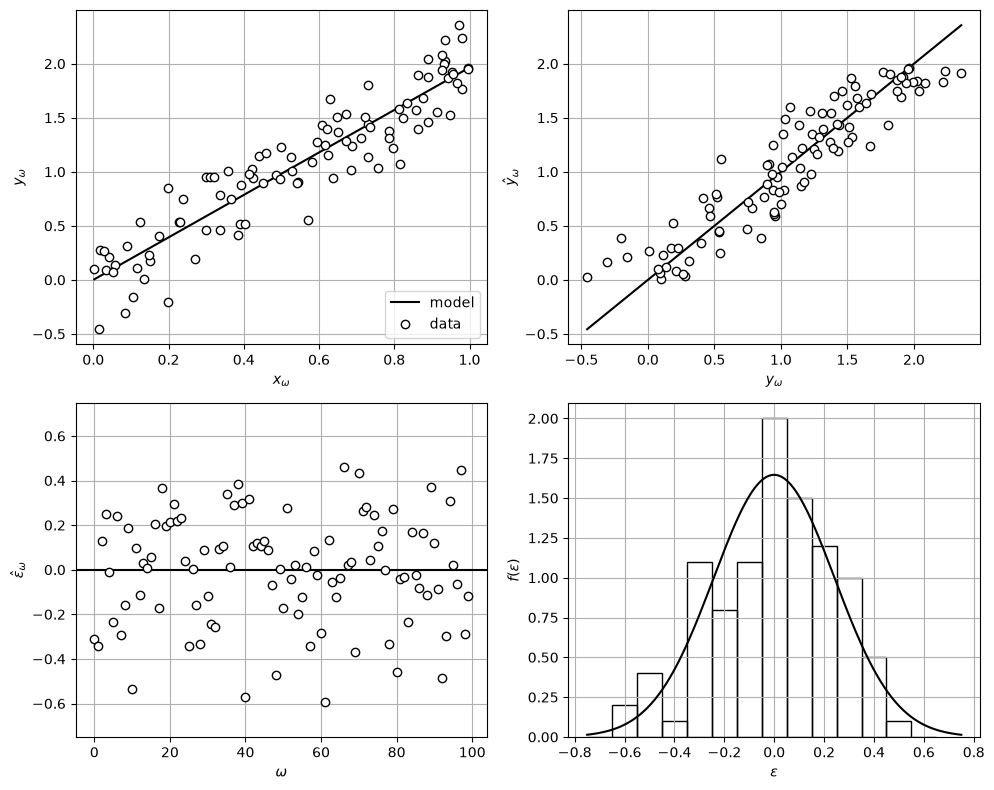

In [2]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
order = np.argsort(x_omega)
axs[0, 0].plot(x_omega[order], y_hat[order], 'k-', linewidth=1.5, label='model')
axs[0, 0].plot(x_omega, y_omega, 'ko', markerfacecolor='w', label='data')
axs[0, 0].set_xlabel(r'$x_\omega$'); axs[0, 0].set_ylabel(r'$y_\omega$'); axs[0, 0].legend(loc='lower right')
lims = [y_omega.min(), y_omega.max()]
axs[0, 1].plot(lims, lims, 'k-')
axs[0, 1].plot(y_omega, y_hat, 'ko', markerfacecolor='w')
axs[0, 1].set_xlabel(r'$y_\omega$'); axs[0, 1].set_ylabel(r'$\hat{y}_\omega$')
axs[1, 0].axhline(0, color='k')
axs[1, 0].plot(eps_hat, 'ko', markerfacecolor='w')
axs[1, 0].set_ylim(-3*sigma, 3*sigma)
axs[1, 0].set_xlabel(r'$\omega$'); axs[1, 0].set_ylabel(r'$\hat{\epsilon}_\omega$')
e = np.linspace(-0.75, 0.75, 200)
axs[1, 1].hist(eps_hat, bins=np.arange(-0.75, 0.75, 0.1), density=True, edgecolor='black', facecolor='none')
axs[1, 1].plot(e, norm.pdf(e, mu_eps, sigma_eps), 'k-', linewidth=1.5)
axs[1, 1].set_xlabel(r'$\epsilon$'); axs[1, 1].set_ylabel(r'$f(\epsilon)$')
for ax in axs.ravel():
    ax.grid(True)
plt.tight_layout()
plt.show()

$SSE(\theta)=\frac{1}{2}\sum_\omega(y_\omega-\theta x_\omega)^2$ (scaled by $1/S$) becomes sharper as $S$ grows.

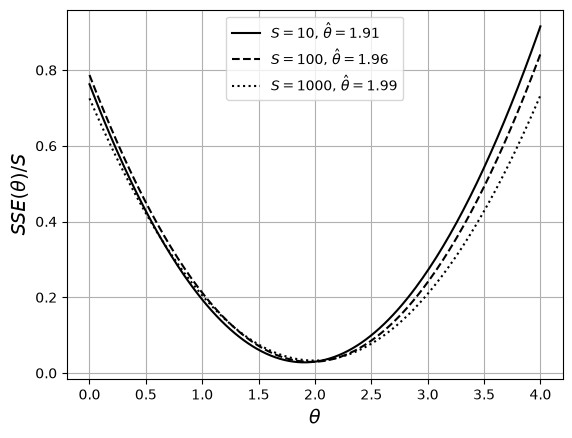

In [3]:
theta_grid = np.linspace(0, 4, 200)
for S, style in ((10, 'k-'), (100, 'k--'), (1000, 'k:')):
    x_omega, y_omega = generate(S)
    SSE = np.array([0.5 * np.sum((y_omega - th * x_omega)**2) for th in theta_grid])
    theta_hat = np.sum(x_omega * y_omega) / np.sum(x_omega**2)
    plt.plot(theta_grid, SSE / S, style, linewidth=1.5, label=rf'$S={S}$, $\hat\theta={theta_hat:.2f}$')
plt.grid(True)
plt.xlabel(r'$\theta$', fontsize=14)
plt.ylabel(r'$SSE(\theta)/S$', fontsize=14)
plt.legend()
plt.show()

**The Fisher information.** Here $\mathcal{I}=\sum_\omega x_\omega^2/\sigma^2$ and $\mathbb{V}[\hat{\theta}]=1/\mathcal{I}$. Repeating the experiment many times with the same inputs, the spread of $\hat{\theta}$ matches the formula. Larger inputs carry more information for this model.

In [4]:
rng = np.random.default_rng(1)
for name, x_d in (("x uniform in [0, 1]", rng.random(100)), ("x = 1 in all runs  ", np.ones(100))):
    Y = theta * x_d + rng.normal(0, sigma, (5000, 100))
    est = Y @ x_d / np.sum(x_d**2)
    print(f"{name}: SD of the estimates = {est.std():.4f},  1/sqrt(I) = {sigma / np.sqrt(np.sum(x_d**2)):.4f}")

x uniform in [0, 1]: SD of the estimates = 0.0434,  1/sqrt(I) = 0.0425
x = 1 in all runs  : SD of the estimates = 0.0252,  1/sqrt(I) = 0.0250


**Note:** As in the book, with S = 10 the SSE is minimized at theta of about 2.2, and with S = 100 or 1000 close to 2: more data helps identify the true parameter.